# Random forest — FAO land suitability
**Virginia tobacco, Regions I & II**

Second of the three models. The spatial holdout uses the **same seed and the same
stratified-block logic** as the ordinal logistic regression, so the two are evaluated on
identical held-out blocks and the comparison is like-for-like.

Differences from the baseline, all deliberate:

| | Ordinal LR | Random forest |
|---|---|---|
| Transforms | log1p, z-score, squared terms | **none** — trees are monotone-invariant |
| Aspect | sin/cos of degrees | `northness` / `eastness` directly |
| Collinearity | screened by VIF | tolerated; handled by permutation importance |
| Ordinality | modelled explicitly | not modelled — checked via quadratic weighted kappa |

Run in order. Everything stays in memory, so a cell can be re-run on its own.

## Setup

In [1]:
# !pip install scikit-learn pyarrow matplotlib joblib -q
import os, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, cohen_kappa_score, confusion_matrix,
                             accuracy_score, classification_report)
from sklearn.model_selection import StratifiedGroupKFold
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 60)

DATA_PATH = r"D:\Projects\capstone\feature_matrix.parquet"
OUT_DIR   = r"D:\Projects\capstone\rf_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
p_out = lambda n: os.path.join(OUT_DIR, n)

TARGET, BLOCK, REGION = "fao_class", "spatial_block", "region"
ORDER = ["N", "S3", "S2", "S1"]        # low -> high suitability
SEED  = 42                             # same as the ordinal LR holdout

N_TREES      = 400
MAX_FEATURES = "sqrt"
MIN_LEAF     = 5
FEATURE_SET  = "all"                   # "all" or "selected"
PERM_SAMPLE  = 40_000                  # rows used for permutation importance

T0 = time.time()
tick = lambda m: print(f"[{(time.time()-T0)/60:6.1f} min] {m}", flush=True)
print("ready")

ready


## Stage 0 — Load and reproduce the same spatial holdout

Identical seed and block-stratification rule as the ordinal model, so the held-out
blocks are the same set. **Check that the holdout class counts match what the LR
notebook reported** — if they differ, the comparison is not like-for-like.

In [2]:
tick("loading")
df = pd.read_parquet(DATA_PATH).dropna(subset=[TARGET]).reset_index(drop=True)

rng = np.random.default_rng(SEED)
test_blocks = []
for _, g in df.groupby(REGION):
    has_rare = g.groupby(BLOCK)[TARGET].apply(lambda s: (s == ORDER[-1]).any())
    for flag in (True, False):
        b = has_rare[has_rare == flag].index.to_numpy()
        if len(b):
            test_blocks += list(rng.choice(b, size=max(1, int(0.2*len(b))), replace=False))

is_test = df[BLOCK].isin(test_blocks)
train = df[~is_test].reset_index(drop=True)
test  = df[is_test].reset_index(drop=True)

print(f"train {len(train):,} | holdout {len(test):,} over {len(test_blocks)} blocks")
pd.DataFrame({"train": train[TARGET].value_counts().reindex(ORDER),
              "holdout": test[TARGET].value_counts().reindex(ORDER)})

[   0.0 min] loading
train 303,096 | holdout 72,026 over 105 blocks


,train,holdout
fao_class,,
N,96141,23859
S3,95705,24295
S2,98014,21986
S1,13236,1886


## Stage 1 — Features

No transforms. Trees split on order, so monotone transforms (log1p, z-scoring) change
nothing, and the squared terms the LR needed for optimum bands are unnecessary — a tree
represents "too low and too high are both worse" with two splits.

`aspect` is dropped in favour of `northness` / `eastness`: aspect in degrees is circular,
so a split at 0°/360° would separate two nearly identical directions.

In [3]:
DROP = {TARGET, "fao_class_maxlim", "fao_class_storie", "index_sqrt",
        "index_storie", "limiting_factor", "region", "province", "row", "col",
        "x", "y", BLOCK, "sample_weight", "aspect"}

ALL_FEATURES = [c for c in df.columns
                if c not in DROP and df[c].dtype.kind in "fiu"]

# the 18 variables the ordinal model retained, for a like-for-like option
SELECTED = ["soil_ph", "slope_pct", "temp_gs_mean", "ndmi_median", "twi",
            "sand_pct", "clay_pct", "soc", "cec", "rain_dryseason", "elevation",
            "northness", "eastness", "water_freq", "awc", "tpi",
            "soil_moist_med", "ndmi_range_med", "solar_rad_iqr"]

FEATURES = ALL_FEATURES if FEATURE_SET == "all" else [c for c in SELECTED if c in ALL_FEATURES]

X_tr, y_tr = train[FEATURES], train[TARGET]
X_te, y_te = test[FEATURES],  test[TARGET]
code_of = {c: i for i, c in enumerate(ORDER)}
y_tr_k, y_te_k = y_tr.map(code_of).to_numpy(), y_te.map(code_of).to_numpy()

print(f"{len(FEATURES)} features ({FEATURE_SET})")
print(f"NaNs in train: {int(X_tr.isna().sum().sum())}  holdout: {int(X_te.isna().sum().sum())}")
pd.Series(FEATURES, name="feature").to_frame()

32 features (all)
NaNs in train: 0  holdout: 0


,feature
0,elevation
1,slope_pct
2,tpi
3,twi
4,northness
5,eastness
6,sand_pct
7,clay_pct
8,soil_ph
9,soc


## Stage 2 — Fit

`class_weight="balanced_subsample"` reweights within each bootstrap sample, which matters
because S1 is 0.04% of the population even after the stratified draw.

The out-of-bag score is a free internal estimate, but it is **optimistic here**: OOB
samples are spatially adjacent to in-bag ones, so neighbouring correlated cells leak.
Treat the blocked CV and the holdout as the real numbers.

In [4]:
tick(f"fitting {N_TREES} trees on {len(X_tr):,} rows")
rf = RandomForestClassifier(
    n_estimators=N_TREES, max_features=MAX_FEATURES, min_samples_leaf=MIN_LEAF,
    class_weight="balanced_subsample", oob_score=True, bootstrap=True,
    n_jobs=-1, random_state=SEED)
rf.fit(X_tr, y_tr)
tick("done")

print(f"OOB accuracy (optimistic — spatial leakage): {rf.oob_score_:.4f}")
print(f"classes: {list(rf.classes_)}")
joblib.dump({"model": rf, "features": FEATURES, "order": ORDER},
            p_out("rf_model.joblib"))
print("model saved")

[   0.0 min] fitting 400 trees on 303,096 rows
[   3.4 min] done
OOB accuracy (optimistic — spatial leakage): 0.9642
classes: ['N', 'S1', 'S2', 'S3']
model saved


## Stage 3 — Holdout performance

Four metrics, each answering a different question:

- **accuracy** — exact agreement
- **macro-F1** — equal weight per class, so the rare S1 counts as much as N
- **kappa** — chance-corrected agreement
- **quadratic weighted kappa** — the right metric for an ordered target: an N→S1 error is
  penalised nine times as heavily as an N→S3 error

In [17]:
pred = rf.predict(X_te)
pred_k = pd.Series(pred).map(code_of).to_numpy()

def scores(true_k, p_k, label):
    return dict(subset=label, n=len(true_k),
                accuracy=accuracy_score(true_k, p_k),
                macroF1=f1_score(true_k, p_k, average="macro"),
                kappa=cohen_kappa_score(true_k, p_k),
                kappa_quadratic=cohen_kappa_score(true_k, p_k, weights="quadratic"),
                within_one=np.mean(np.abs(true_k - p_k) <= 1))

rows = [scores(y_te_k, pred_k, "holdout (all)")]
for r in sorted(test[REGION].unique()):
    m = (test[REGION] == r).to_numpy()
    rows.append(scores(y_te_k[m], pred_k[m], f"holdout Region {r}"))
res = pd.DataFrame(rows)
res.to_csv(p_out("rf_holdout_scores.csv"), index=False)
res.round(4)

,subset,n,accuracy,macroF1,kappa,kappa_quadratic,within_one
0,holdout (all),72026,0.9752,0.9774,0.9636,0.9832,1.0
1,holdout Region I,24685,0.9720,0.9745,0.9602,0.9844,1.0
2,holdout Region II,47341,0.9768,0.9752,0.9652,0.9819,1.0


In [18]:
cm = pd.DataFrame(confusion_matrix(y_te_k, pred_k, labels=range(len(ORDER))),
                  index=[f"true_{c}" for c in ORDER],
                  columns=[f"pred_{c}" for c in ORDER])
cm.to_csv(p_out("rf_holdout_confusion.csv"))
print("recall per class (%):")
print((cm.div(cm.sum(axis=1), axis=0) * 100).round(1).to_string())
print()
print(classification_report(y_te_k, pred_k, target_names=ORDER, digits=3))
cm

recall per class (%):
         pred_N  pred_S3  pred_S2  pred_S1
true_N     99.0      1.0      0.0      0.0
true_S3     0.3     97.2      2.4      0.0
true_S2     0.0      3.7     96.1      0.1
true_S1     0.0      0.0      1.3     98.7

              precision    recall  f1-score   support

           N      0.997     0.990     0.993     23859
          S3      0.957     0.972     0.965     24295
          S2      0.972     0.961     0.967     21986
          S1      0.984     0.987     0.985      1886

    accuracy                          0.975     72026
   macro avg      0.977     0.978     0.977     72026
weighted avg      0.975     0.975     0.975     72026



,pred_N,pred_S3,pred_S2,pred_S1
true_N,23614,245,0,0
true_S3,81,23626,588,0
true_S2,0,819,21136,31
true_S1,0,0,25,1861


## Stage 4 — Spatially blocked cross-validation

Whole blocks stay together and classes are balanced across folds. This is the number
comparable to the ordinal model's 0.858.

In [19]:
tick("blocked CV")
cv_rows = []
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (tr_i, va_i) in enumerate(splitter.split(X_tr, y_tr, train[BLOCK]), 1):
    m = RandomForestClassifier(n_estimators=200, max_features=MAX_FEATURES,
                               min_samples_leaf=MIN_LEAF,
                               class_weight="balanced_subsample",
                               n_jobs=-1, random_state=SEED)
    m.fit(X_tr.iloc[tr_i], y_tr.iloc[tr_i])
    pk = pd.Series(m.predict(X_tr.iloc[va_i])).map(code_of).to_numpy()
    tk = y_tr_k[va_i]
    cv_rows.append(dict(fold=k, macroF1=f1_score(tk, pk, average="macro"),
                        kappa=cohen_kappa_score(tk, pk),
                        kappa_quadratic=cohen_kappa_score(tk, pk, weights="quadratic")))
    tick(f"  fold {k}: macroF1={cv_rows[-1]['macroF1']:.3f}")

cv = pd.DataFrame(cv_rows)
cv.loc["mean"] = cv.mean(numeric_only=True)
cv.loc["sd"] = pd.DataFrame(cv_rows).std(numeric_only=True)
cv.to_csv(p_out("rf_cv.csv"))
cv.round(4)

[2830.3 min] blocked CV
[2831.1 min]   fold 1: macroF1=0.959
[2831.8 min]   fold 2: macroF1=0.966
[2832.4 min]   fold 3: macroF1=0.979
[2833.1 min]   fold 4: macroF1=0.975
[2833.8 min]   fold 5: macroF1=0.974


,fold,macroF1,kappa,kappa_quadratic
0,1.0000,0.9590,0.9329,0.9723
1,2.0000,0.9657,0.9594,0.9820
2,3.0000,0.9792,0.9661,0.9858
3,4.0000,0.9752,0.9634,0.9838
4,5.0000,0.9738,0.9587,0.9817
mean,3.0000,0.9706,0.9561,0.9811
sd,1.5811,0.0082,0.0133,0.0052


In [23]:
from sklearn.model_selection import StratifiedKFold, GroupKFold
from sklearn.base import clone
import numpy as np, pandas as pd

tick("overfitting diagnostics")
sm = lambda t, p: f1_score(t, p, average="macro")

# --- 1. train vs OOB vs holdout -------------------------------------
tr_pred = pd.Series(rf.predict(X_tr)).map(code_of).to_numpy()
print(f"train   macroF1 {sm(y_tr_k, tr_pred):.4f}   acc {accuracy_score(y_tr_k, tr_pred):.4f}")
print(f"OOB     acc     {rf.oob_score_:.4f}")
print(f"holdout macroF1 {sm(y_te_k, pred_k):.4f}   acc {accuracy_score(y_te_k, pred_k):.4f}")

# --- 2. THE key test: random split vs spatially blocked -------------
base = lambda: RandomForestClassifier(n_estimators=150, max_features=MAX_FEATURES,
        min_samples_leaf=MIN_LEAF, class_weight="balanced_subsample",
        n_jobs=-1, random_state=SEED)

rand_s, blk_s = [], []
for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tr, y_tr):
    m = base().fit(X_tr.iloc[tr_i], y_tr.iloc[tr_i])
    rand_s.append(sm(y_tr_k[va_i], pd.Series(m.predict(X_tr.iloc[va_i])).map(code_of)))
for tr_i, va_i in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(
        X_tr, y_tr, train[BLOCK]):
    m = base().fit(X_tr.iloc[tr_i], y_tr.iloc[tr_i])
    blk_s.append(sm(y_tr_k[va_i], pd.Series(m.predict(X_tr.iloc[va_i])).map(code_of)))

print(f"\nrandom 5-fold CV   {np.mean(rand_s):.4f}  (sd {np.std(rand_s):.4f})")
print(f"blocked 5-fold CV  {np.mean(blk_s):.4f}  (sd {np.std(blk_s):.4f})")
print(f"spatial leakage    {np.mean(rand_s) - np.mean(blk_s):+.4f}")

# --- 3. does restricting capacity change anything? ------------------
print("\nmin_samples_leaf | train | holdout")
for leaf in [1, 5, 20, 100, 500]:
    m = RandomForestClassifier(n_estimators=150, max_features=MAX_FEATURES,
            min_samples_leaf=leaf, class_weight="balanced_subsample",
            n_jobs=-1, random_state=SEED).fit(X_tr, y_tr)
    a = sm(y_tr_k, pd.Series(m.predict(X_tr)).map(code_of))
    b = sm(y_te_k, pd.Series(m.predict(X_te)).map(code_of))
    print(f"  {leaf:>5}          {a:.4f}  {b:.4f}   gap {a-b:+.4f}")

# --- 4. learning curve ----------------------------------------------
print("\ntrain size | holdout macroF1")
rs = np.random.default_rng(SEED)
for frac in [0.05, 0.1, 0.25, 0.5, 1.0]:
    i = rs.choice(len(X_tr), int(frac*len(X_tr)), replace=False)
    m = base().fit(X_tr.iloc[i], y_tr.iloc[i])
    print(f"  {len(i):>7,}   {sm(y_te_k, pd.Series(m.predict(X_te)).map(code_of)):.4f}")

# --- 5. shuffled-label control --------------------------------------
y_sh = y_tr.sample(frac=1, random_state=SEED).reset_index(drop=True)
m = base().fit(X_tr, y_sh)
print(f"\nshuffled labels -> holdout macroF1 "
      f"{sm(y_te_k, pd.Series(m.predict(X_te)).map(code_of)):.4f}  (chance ~0.25)")

[2958.8 min] overfitting diagnostics
train   macroF1 0.9935   acc 0.9940
OOB     acc     0.9791
holdout macroF1 0.9774   acc 0.9752

random 5-fold CV   0.9804  (sd 0.0008)
blocked 5-fold CV  0.9708  (sd 0.0071)
spatial leakage    +0.0096

min_samples_leaf | train | holdout
      1          1.0000  0.9669   gap +0.0331
      5          0.9934  0.9770   gap +0.0164
     20          0.9822  0.9729   gap +0.0092
    100          0.9639  0.9608   gap +0.0030
    500          0.9323  0.9373   gap -0.0050

train size | holdout macroF1
   15,154   0.9548
   30,309   0.9629
   75,774   0.9707
  151,548   0.9735
  303,096   0.9769

shuffled labels -> holdout macroF1 0.2500  (chance ~0.25)


In [13]:
tick("leaf size by blocked CV (not holdout)")
rows = []
for leaf in [5, 10, 20, 35, 50, 100]:
    sc = []
    for tr_i, va_i in StratifiedGroupKFold(5, shuffle=True,
                                           random_state=SEED).split(X_tr, y_tr, train[BLOCK]):
        m = RandomForestClassifier(n_estimators=150, max_features=MAX_FEATURES,
                min_samples_leaf=leaf, class_weight="balanced_subsample",
                n_jobs=-1, random_state=SEED).fit(X_tr.iloc[tr_i], y_tr.iloc[tr_i])
        sc.append(f1_score(y_tr_k[va_i],
                  pd.Series(m.predict(X_tr.iloc[va_i])).map(code_of), average="macro"))
    rows.append(dict(min_samples_leaf=leaf, cv_macroF1=np.mean(sc), sd=np.std(sc)))
    print(f"  leaf {leaf:>3}: {np.mean(sc):.4f} (sd {np.std(sc):.4f})")

best = max(rows, key=lambda r: r["cv_macroF1"])["min_samples_leaf"]
print(f"\nselected min_samples_leaf = {best}")
pd.DataFrame(rows).to_csv(p_out("rf_leaf_tuning.csv"), index=False)

[2553.7 min] leaf size by blocked CV (not holdout)
  leaf   5: 0.9447 (sd 0.0081)
  leaf  10: 0.9421 (sd 0.0088)
  leaf  20: 0.9415 (sd 0.0080)
  leaf  35: 0.9378 (sd 0.0085)
  leaf  50: 0.9347 (sd 0.0091)
  leaf 100: 0.9255 (sd 0.0110)

selected min_samples_leaf = 5


## Stage 5 — Rule vs non-rule ablation

The decisive test for circularity, repeated for the forest. Ten predictors entered the
labelling rule; twenty-one did not. If the non-rule set predicts well, environmental
observation substitutes for the FAO inputs — a real finding. If it does not, the
classification is driven entirely by its own defining criteria.

In [8]:
tick("ablation")
RULE = ["soil_ph", "slope_pct", "temp_gs_mean", "soc", "cec", "sand_pct",
        "clay_pct", "ndmi_median", "twi", "sunshine_rad"]
rule_f = [c for c in RULE if c in FEATURES]
free_f = [c for c in FEATURES if c not in rule_f]

abl = []
for name, cols in [("rule predictors only", rule_f),
                   ("non-rule predictors only", free_f),
                   ("all predictors", FEATURES)]:
    f1s, kqs = [], []
    for tr_i, va_i in splitter.split(X_tr, y_tr, train[BLOCK]):
        m = RandomForestClassifier(n_estimators=150, max_features=MAX_FEATURES,
                                   min_samples_leaf=MIN_LEAF,
                                   class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=SEED)
        m.fit(X_tr.iloc[tr_i][cols], y_tr.iloc[tr_i])
        pk = pd.Series(m.predict(X_tr.iloc[va_i][cols])).map(code_of).to_numpy()
        tk = y_tr_k[va_i]
        f1s.append(f1_score(tk, pk, average="macro"))
        kqs.append(cohen_kappa_score(tk, pk, weights="quadratic"))
    abl.append(dict(predictors=name, n=len(cols), macroF1=np.mean(f1s),
                    macroF1_sd=np.std(f1s), kappa_quadratic=np.mean(kqs)))
    tick(f"  {name}: {abl[-1]['macroF1']:.3f}")

abl = pd.DataFrame(abl)
abl.to_csv(p_out("rf_ablation.csv"), index=False)
abl.round(4)

[   8.3 min] ablation
[  10.0 min]   rule predictors only: 0.967
[  12.1 min]   non-rule predictors only: 0.621
[  14.6 min]   all predictors: 0.945


,predictors,n,macroF1,macroF1_sd,kappa_quadratic
0,rule predictors only,10,0.9673,0.0073,0.9788
1,non-rule predictors only,22,0.6210,0.0592,0.7046
2,all predictors,32,0.9447,0.0081,0.9651


In [15]:
tick("max_features for the rule-only model")
for mf in ["sqrt", 0.5, 0.75, None]:
    sc = []
    for tr_i, va_i in StratifiedGroupKFold(5, shuffle=True,
                                           random_state=SEED).split(X_tr, y_tr, train[BLOCK]):
        m = RandomForestClassifier(n_estimators=150, max_features=mf,
                min_samples_leaf=MIN_LEAF, class_weight="balanced_subsample",
                n_jobs=-1, random_state=SEED).fit(X_tr.iloc[tr_i][rule_f], y_tr.iloc[tr_i])
        sc.append(f1_score(y_tr_k[va_i],
                  pd.Series(m.predict(X_tr.iloc[va_i][rule_f])).map(code_of), average="macro"))
    print(f"  rule-only, max_features={str(mf):>5}: {np.mean(sc):.4f} (sd {np.std(sc):.4f})")

[2651.3 min] max_features for the rule-only model
  rule-only, max_features= sqrt: 0.9673 (sd 0.0073)
  rule-only, max_features=  0.5: 0.9708 (sd 0.0071)
  rule-only, max_features= 0.75: 0.9706 (sd 0.0069)
  rule-only, max_features= None: 0.9685 (sd 0.0071)


In [16]:
FEATURES, MAX_FEATURES = rule_f, 0.5
X_tr, X_te = train[FEATURES], test[FEATURES]

tick(f"final model: {len(FEATURES)} features, max_features={MAX_FEATURES}")
rf = RandomForestClassifier(
    n_estimators=N_TREES, max_features=MAX_FEATURES, min_samples_leaf=MIN_LEAF,
    class_weight="balanced_subsample", oob_score=True, bootstrap=True,
    n_jobs=-1, random_state=SEED).fit(X_tr, y_tr)
tick("done")

joblib.dump({"model": rf, "features": FEATURES, "order": ORDER,
             "max_features": MAX_FEATURES, "min_samples_leaf": MIN_LEAF},
            p_out("rf_model_final.joblib"))
print("OOB:", round(rf.oob_score_, 4))
print("features:", FEATURES)

[2666.2 min] final model: 10 features, max_features=0.5
[2668.4 min] done
OOB: 0.9791
features: ['soil_ph', 'slope_pct', 'temp_gs_mean', 'soc', 'cec', 'sand_pct', 'clay_pct', 'ndmi_median', 'twi', 'sunshine_rad']


## Stage 6 — Permutation importance on held-out data

**Not** `rf.feature_importances_`. Impurity importance is biased toward continuous and
high-cardinality predictors and is computed on training data, so it rewards overfitting.
Permutation importance on the holdout measures what the model actually relies on to
generalise.

Caveat to state in the write-up: with correlated predictors, permuting one lets a
correlated partner carry its signal, so importance is shared and individually understated.
That is also why ALE, not SHAP, is the right attribution method here.

[2833.8 min] permutation importance


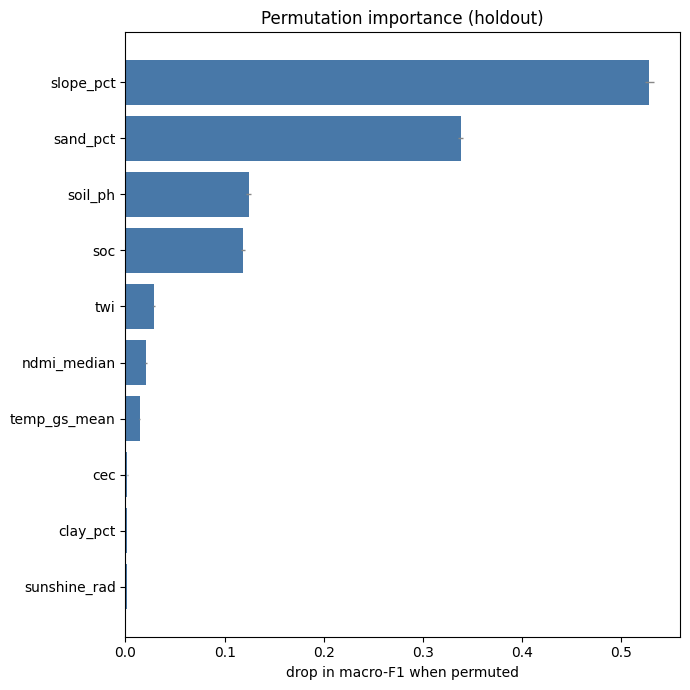

,feature,importance,sd
0,slope_pct,0.52809,0.00444
1,sand_pct,0.33807,0.00238
2,soil_ph,0.12418,0.00240
3,soc,0.11850,0.00220
4,twi,0.02896,0.00094
5,ndmi_median,0.02047,0.00081
6,temp_gs_mean,0.01435,0.00047
7,cec,0.00175,0.00032
8,clay_pct,0.00174,0.00018
9,sunshine_rad,0.00166,0.00019


In [20]:
tick("permutation importance")
idx = np.random.default_rng(SEED).choice(len(X_te), min(PERM_SAMPLE, len(X_te)),
                                         replace=False)
pi = permutation_importance(rf, X_te.iloc[idx], y_te.iloc[idx],
                            scoring="f1_macro", n_repeats=5,
                            random_state=SEED, n_jobs=-1)
imp = (pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean,
                     "sd": pi.importances_std})
       .sort_values("importance", ascending=False).reset_index(drop=True))
imp.to_csv(p_out("rf_permutation_importance.csv"), index=False)

top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top["feature"], top["importance"], xerr=top["sd"],
        color="#4878A8", error_kw=dict(ecolor="#888", lw=1))
ax.set_xlabel("drop in macro-F1 when permuted")
ax.set_title("Permutation importance (holdout)")
fig.tight_layout(); fig.savefig(p_out("rf_permutation_importance.png"), dpi=170)
plt.show()
imp.round(5)

## Stage 7 — Accumulated Local Effects

ALE rather than PDP or SHAP, because the predictors are correlated: PDP averages over
combinations that do not occur (steep slope with deep alluvial soil), and SHAP's
attribution is unstable under collinearity. ALE uses only each feature's local
neighbourhood, so it stays valid.

The response is the **expected suitability level**, Σ j·P(class j) on the 0 = N … 3 = S1
scale, which collapses four class probabilities into one interpretable curve.

[2834.4 min] ALE for the top 6 features


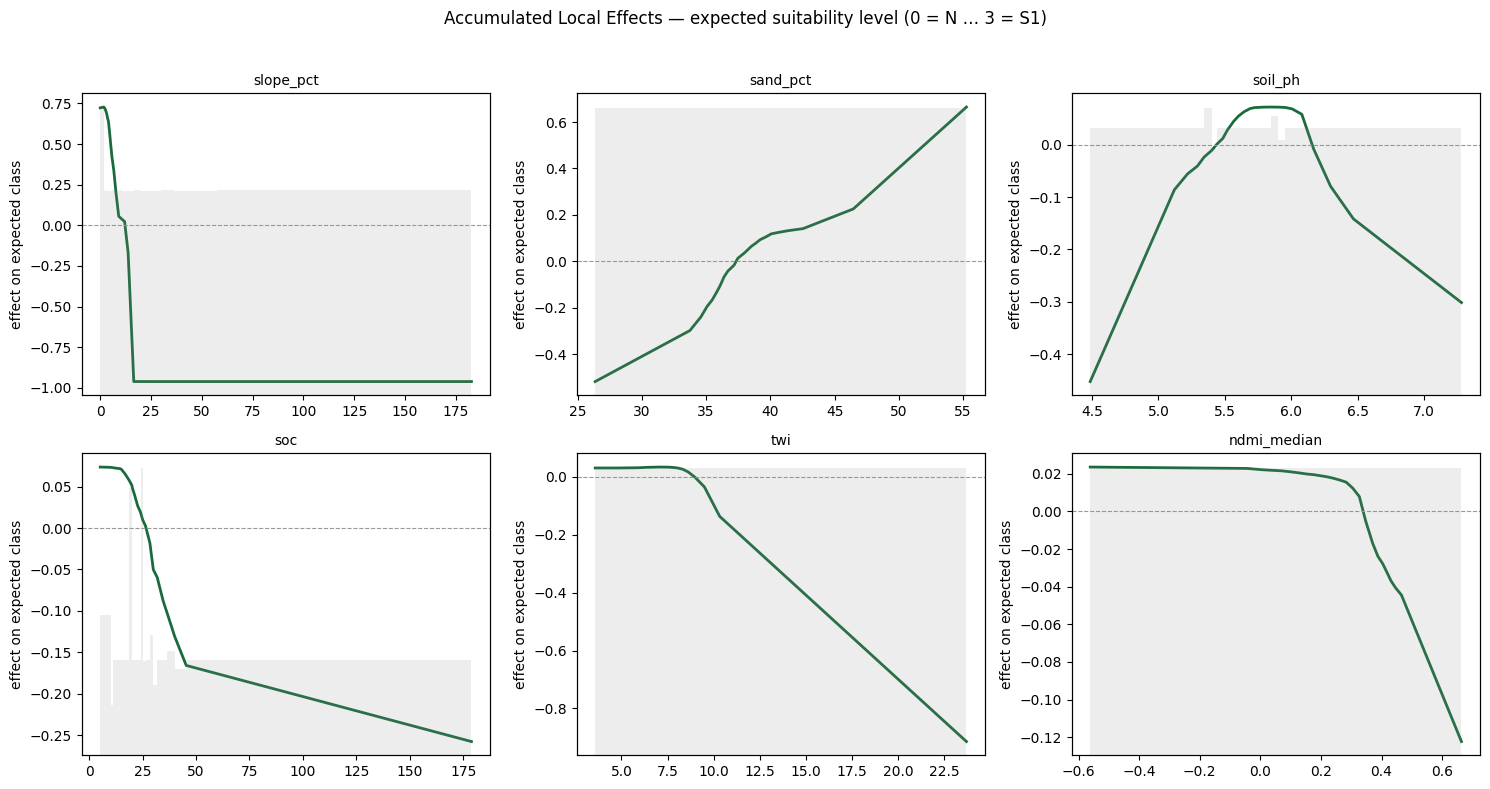

In [21]:
def expected_level(model, X):
    P = model.predict_proba(X)
    lvl = np.array([code_of[c] for c in model.classes_], dtype=float)
    return P @ lvl

def ale_1d(model, X, feature, bins=24, sample=20_000, seed=SEED):
    """First-order ALE on the expected-suitability response."""
    rs = np.random.default_rng(seed)
    if len(X) > sample:
        X = X.iloc[rs.choice(len(X), sample, replace=False)]
    v = X[feature].to_numpy(dtype=float)
    q = np.unique(np.quantile(v, np.linspace(0, 1, bins + 1)))
    if len(q) < 3:
        return None
    k = np.clip(np.searchsorted(q, v, side="left") - 1, 0, len(q) - 2)

    eff = np.zeros(len(q) - 1)
    cnt = np.zeros(len(q) - 1)
    for b in range(len(q) - 1):
        m = k == b
        if not m.any():
            continue
        lo, hi = X[m].copy(), X[m].copy()
        lo[feature], hi[feature] = q[b], q[b + 1]
        eff[b] = np.mean(expected_level(model, hi) - expected_level(model, lo))
        cnt[b] = m.sum()

    ale = np.concatenate([[0.0], np.cumsum(eff)])
    centre = np.sum((ale[:-1] + ale[1:]) / 2 * cnt) / max(cnt.sum(), 1)
    return q, ale - centre, cnt

tick("ALE for the top 6 features")
feats = imp["feature"].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), feats):
    out = ale_1d(rf, X_te, f)
    if out is None:
        ax.set_visible(False); continue
    q, a, c = out
    ax.plot(q, a, lw=2, color="#1a6b3c")
    ax.axhline(0, color="#999", lw=0.8, ls="--")
    ax2 = ax.twinx()
    ax2.bar((q[:-1] + q[1:]) / 2, c, width=np.diff(q), alpha=0.15, color="#888")
    ax2.set_yticks([])
    ax.set_title(f, fontsize=10)
    ax.set_ylabel("effect on expected class")
fig.suptitle("Accumulated Local Effects — expected suitability level (0 = N … 3 = S1)",
             fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(p_out("rf_ale_top6.png"), dpi=170)
plt.show()

## Stage 8 — Comparison against the ordinal baseline

Fill the LR figures in from `fs_cv_comparison.csv` and its holdout confusion matrix.

In [22]:
LR = {"macroF1_cv": 0.858, "macroF1_holdout": 0.837, "kappa_holdout": 0.774,
      "accuracy_holdout": 0.845, "within_one_holdout": 0.9985}

rf_h = res[res["subset"] == "holdout (all)"].iloc[0]
cmp = pd.DataFrame([
    dict(model="Ordinal LR (baseline)", cv_macroF1=LR["macroF1_cv"],
         holdout_macroF1=LR["macroF1_holdout"], holdout_kappa=LR["kappa_holdout"],
         holdout_accuracy=LR["accuracy_holdout"], within_one=LR["within_one_holdout"]),
    dict(model="Random forest", cv_macroF1=cv.loc["mean", "macroF1"],
         holdout_macroF1=rf_h["macroF1"], holdout_kappa=rf_h["kappa"],
         holdout_accuracy=rf_h["accuracy"], within_one=rf_h["within_one"]),
])
cmp.to_csv(p_out("model_comparison.csv"), index=False)
cmp.round(4)

,model,cv_macroF1,holdout_macroF1,holdout_kappa,holdout_accuracy,within_one
0,Ordinal LR (baseline),0.8580,0.8370,0.7740,0.8450,0.9985
1,Random forest,0.9706,0.9774,0.9636,0.9752,1.0000


In [24]:
%run "D:\Projects\capstone\predict_and_map_rf.py"

Random forest: 10 features, 400 trees, max_features=0.5
features: ['soil_ph', 'slope_pct', 'temp_gs_mean', 'soc', 'cec', 'sand_pct', 'clay_pct', 'ndmi_median', 'twi', 'sunshine_rad']
reading 16 source columns from 94 parts
  10/94  3,540,154 cells (0.4 min)
  20/94  6,519,402 cells (0.7 min)
  30/94  9,938,517 cells (1.1 min)
  50/94  22,082,386 cells (2.3 min)
  60/94  28,322,061 cells (2.9 min)
  70/94  29,931,683 cells (3.1 min)
  80/94  32,579,847 cells (3.4 min)
  90/94  39,037,709 cells (4.1 min)
  94/94  41,592,605 cells (4.3 min)

rendering

comparing against the ordinal LR baseline
  cells compared       : 41,592,438
  models agree         : 86.53%
  ordinal LR correct   : 86.97%
  Random forest correct  : 97.95%

  LR (rows) vs RF (columns):
           RF_N    RF_S3    RF_S2  RF_S1
LR_N   21327870  1082959      228      0
LR_S3   1573140  9609205   914456      0
LR_S2     32626  1873351  5028996  24878
LR_S1       987     9702    89094  24946

WALL-TO-WALL PREDICTION — RANDOM

### What to read

- **A large RF advantage** means the labelling rule's non-linearity and interactions are
  what the linear model could not reach — expected, since the rule applies minimum-and-
  product aggregation over non-linear rating curves.
- **A small advantage** means the relationship is close to monotone once the optimum-band
  terms are included, and the simpler model should be preferred for interpretation.
- **Per-region holdout rows** matter as much as the overall figure: S1 is 95% Region I, so
  stable Region II performance is what shows the model is not keyed to geography.
- **The ablation is the one to foreground.** If the non-rule predictors still trail badly
  for the forest too, that is the circularity result confirmed under a model class that
  cannot be accused of being too rigid to find the signal.